In [21]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [22]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:

pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
pip version sklearn

Note: you may need to restart the kernel to use updated packages.


ERROR: unknown command "version"



In [27]:
%cd  C:\Users\engza\OneDrive\Desktop\project

C:\Users\engza\OneDrive\Desktop\project


In [28]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))
from Helper.helper import predict_rul

In [29]:
import numpy as np                        # numbers
import pandas as pd                       # tables
import matplotlib.pyplot as plt           # charts
import joblib                             # save / load models
# scikit-learn tools (we will meet each one when we use it)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

np.random.seed(42)                        # fixed seed -> same results every run
print("Libraries loaded ✅")

Libraries loaded ✅


In [30]:
from pathlib import Path

project_dir = Path.cwd()
if project_dir.name == "Notebooks":
    project_dir = project_dir.parent

train_path = project_dir / "Data" / "Original" / "train_FD001.txt"

print(train_path)
print("File exists:", train_path.is_file())

C:\Users\engza\OneDrive\Desktop\project\Data\Original\train_FD001.txt
File exists: True


In [31]:
df = pd.read_csv(train_path, sep=r"\s+", header=None)

In [32]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
df.head()

Shape: (20631, 26)
Columns: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [33]:
df.info()   # info() shows each column, its data type, and how many values are NOT missing

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       20631 non-null  int64  
 1   1       20631 non-null  int64  
 2   2       20631 non-null  float64
 3   3       20631 non-null  float64
 4   4       20631 non-null  float64
 5   5       20631 non-null  float64
 6   6       20631 non-null  float64
 7   7       20631 non-null  float64
 8   8       20631 non-null  float64
 9   9       20631 non-null  float64
 10  10      20631 non-null  float64
 11  11      20631 non-null  float64
 12  12      20631 non-null  float64
 13  13      20631 non-null  float64
 14  14      20631 non-null  float64
 15  15      20631 non-null  float64
 16  16      20631 non-null  float64
 17  17      20631 non-null  float64
 18  18      20631 non-null  float64
 19  19      20631 non-null  float64
 20  20      20631 non-null  float64
 21  21      20631 non-null  int64  
 22  22      2

In [34]:
missing_markers = {"", "non", "none", "null", "na", "n/a", "nan", "-"}


text_values = df.astype("string").apply(
    lambda column: column.str.strip().str.lower()
)

missing_mask = df.isna() | text_values.isin(missing_markers)

missing_counts = missing_mask.sum()
print("Total missing values:", missing_counts.sum())
display(missing_counts[missing_counts > 0])

Total missing values: 0


Series([], dtype: int64)

In [35]:
df.describe() # describe() gives quick statistics (mean, min, max...) for the numeric columns


,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,521.413470,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.737553,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,518.690000,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,520.960000,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,521.480000,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,521.950000,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,523.380000,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400


******# Split the columns by type******


In [36]:
# Split the columns by type
numeric_cols = df.select_dtypes(include="number").columns.tolist()
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
print(f"\nNumerical columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Text columns ({len(text_cols)}): {text_cols}")


Numerical columns (26): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Text columns (0): []


Check Missing values and duplicate values


In [37]:
# Count missing values in each column (isna() marks missing as True, sum() counts them)
print("Missing values per column:")
print(df.isna().sum())

# Count rows that are exact copies of an earlier row
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     0
8     0
9     0
10    0
11    0
12    0
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    0
21    0
22    0
23    0
24    0
25    0
dtype: int64

Duplicate rows: 0


In [38]:
# Count and percentage of missing values per column
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(1),
})
print("--- COLUMNS WITH MISSING VALUES ---")
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))

--- COLUMNS WITH MISSING VALUES ---


,missing_count,missing_pct


In [39]:
# df.columns = (
#     ["engine_id", "cycle"]
#     + [f"setting_{i}" for i in range(1, 4)]
#     + [f"sensor_{i}" for i in range(1, 22)]


# display(df.head())

In [40]:
# عدد الصفوف والأعمدة
print("Shape:", df.shape)

# عدد المحركات
print("Number of engines:", df["engine_id"].nunique())

# أول وآخر دورة مسجلة لكل محرك
engine_summary = df.groupby("engine_id")["cycle"].agg(
    first_cycle="min",
    last_cycle="max",
    recorded_cycles="count"
)

display(engine_summary.head())

Shape: (20631, 26)


KeyError: 'engine_id'

In [ ]:
# عدد القيم المفقودة في كل عمود
display(df.isna().sum())

# عدد الصفوف المتطابقة بالكامل
print("Duplicate rows:", df.duplicated().sum())

# تكرار تسجيل المحرك نفسه في الدورة نفسها
print(
    "Duplicate engine-cycle pairs:",
    df.duplicated(subset=["engine_id", "cycle"]).sum()
)

engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

Duplicate rows: 0
Duplicate engine-cycle pairs: 0


**No missing values ​​were detected in the data; therefore, we did not apply any imputation.**

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate engine-cycle pairs:",
    df.duplicated(subset=["engine_id", "cycle"]).sum()
)

Duplicate rows: 0
Duplicate engine-cycle pairs: 0


No identical rows or duplicate records for the same engine and cycle were detected; therefore, no records were deleted.

In [ ]:

df["RUL"] = (
    df.groupby("engine_id")["cycle"].transform("max")
    - df["cycle"]
)

display(df[["engine_id", "cycle", "RUL"]].head())

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


#EDA


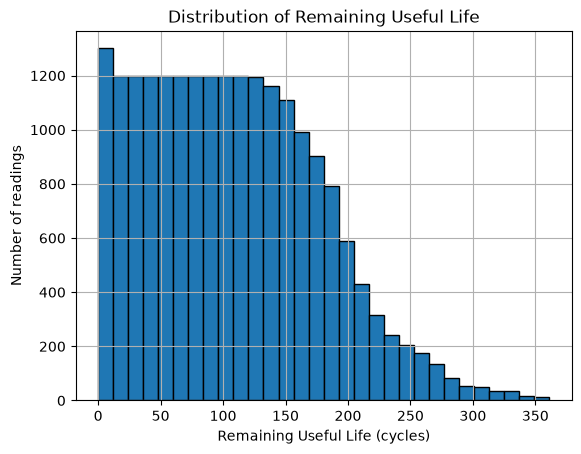

count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

In [ ]:
import matplotlib.pyplot as plt

df["RUL"].hist(bins=30, edgecolor="black")

plt.title("Distribution of Remaining Useful Life")
plt.xlabel("Remaining Useful Life (cycles)")
plt.ylabel("Number of readings")
plt.show()

display(df["RUL"].describe())

### Remaining Useful Life (RUL) Distribution
- Lower RUL values are more frequent, while higher RUL values are less frequent, creating a right-skewed distribution.
- This pattern alone does not indicate errors, so we retain these values without automatic removal or capping.

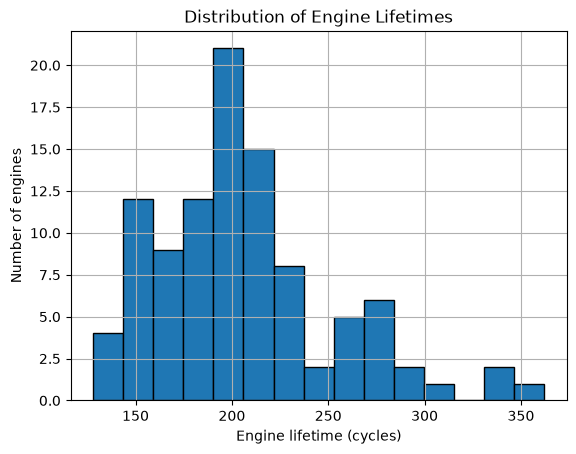

In [ ]:
engine_lifetime = df.groupby("engine_id")["cycle"].max()

engine_lifetime.hist(bins=15, edgecolor="black")

plt.title("Distribution of Engine Lifetimes")
plt.xlabel("Engine lifetime (cycles)")
plt.ylabel("Number of engines")
plt.show()

### Engine Lifespan Distribution
- Engine lifespans vary, with most falling approximately between 140 and 230 cycles and a few lasting longer.
- A longer lifespan alone does not indicate an error, so we retain these engines.

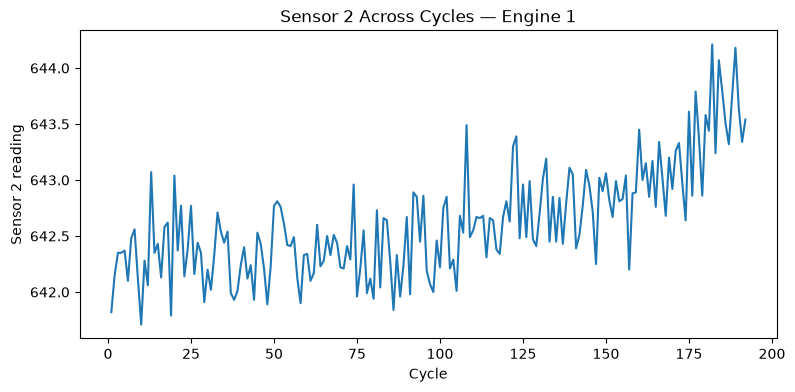

In [ ]:
engine = df[df["engine_id"] == 1].sort_values("cycle")

plt.figure(figsize=(9, 4))
plt.plot(engine["cycle"], engine["sensor_2"])

plt.title("Sensor 2 Across Cycles — Engine 1")
plt.xlabel("Cycle")
plt.ylabel("Sensor 2 reading")
plt.show()

### Sensor 2 Trend — Engine 1
- Sensor 2 shows an upward trend as Engine 1 progresses through its operating cycles, with fluctuations between readings.
- We will examine this relationship across other engines before assessing its usefulness for prediction.

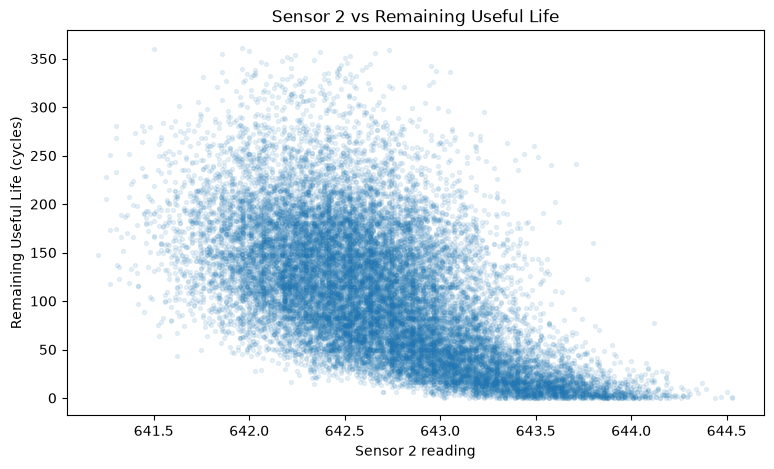

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["sensor_2"],
    df["RUL"],
    alpha=0.1,
    s=8
)

plt.title("Sensor 2 vs Remaining Useful Life")
plt.xlabel("Sensor 2 reading")
plt.ylabel("Remaining Useful Life (cycles)")
plt.show()

### Sensor 2 vs. RUL
- Sensor 2 shows a negative, nonlinear relationship with RUL, with considerable scatter, particularly at lower sensor readings.
- We will retain it as a candidate feature and evaluate its usefulness alongside the other features.

In [ ]:
# نفحص إعدادات التشغيل والمستشعرات فقط
feature_cols = [
    col for col in df.columns
    if col.startswith(("setting_", "sensor_"))
]

unique_counts = df[feature_cols].nunique().sort_values()
display(unique_counts)

# الأعمدة التي تحتوي قيمة واحدة فقط
constant_cols = unique_counts[unique_counts == 1].index.tolist()
print("Constant columns:", constant_cols)

sensor_1        1
setting_3       1
sensor_5        1
sensor_10       1
sensor_18       1
sensor_19       1
sensor_16       1
sensor_6        2
sensor_17      13
setting_2      13
sensor_8       53
sensor_13      56
sensor_20     120
setting_1     158
sensor_11     159
sensor_2      310
sensor_12     427
sensor_7      513
sensor_15    1918
sensor_3     3012
sensor_4     4051
sensor_21    4745
sensor_14    6078
sensor_9     6403
dtype: int64

Constant columns: ['sensor_1', 'setting_3', 'sensor_5', 'sensor_10', 'sensor_18', 'sensor_19', 'sensor_16']


### Constant Features
- Seven constant features were identified and will be excluded from the model inputs.
- The remaining features require further analysis to assess their usefulness in predicting RUL.

C:\Users\engza\AppData\Local\Temp\ipykernel_6948\280013116.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["sensor_2"], vert=False)


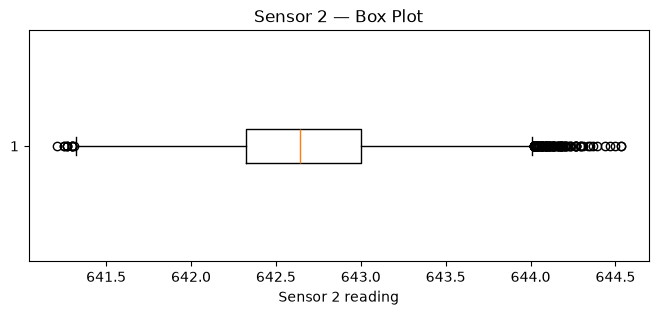

In [ ]:
plt.figure(figsize=(8, 3))
plt.boxplot(df["sensor_2"], vert=False)

plt.title("Sensor 2 — Box Plot")
plt.xlabel("Sensor 2 reading")
plt.show()

### Sensor 2 Outliers
- Statistical outliers are present in Sensor 2, particularly at the upper end.
- We will retain them for now, as there is no evidence that they are errors, and the previous plot showed that higher readings are associated with lower RUL.

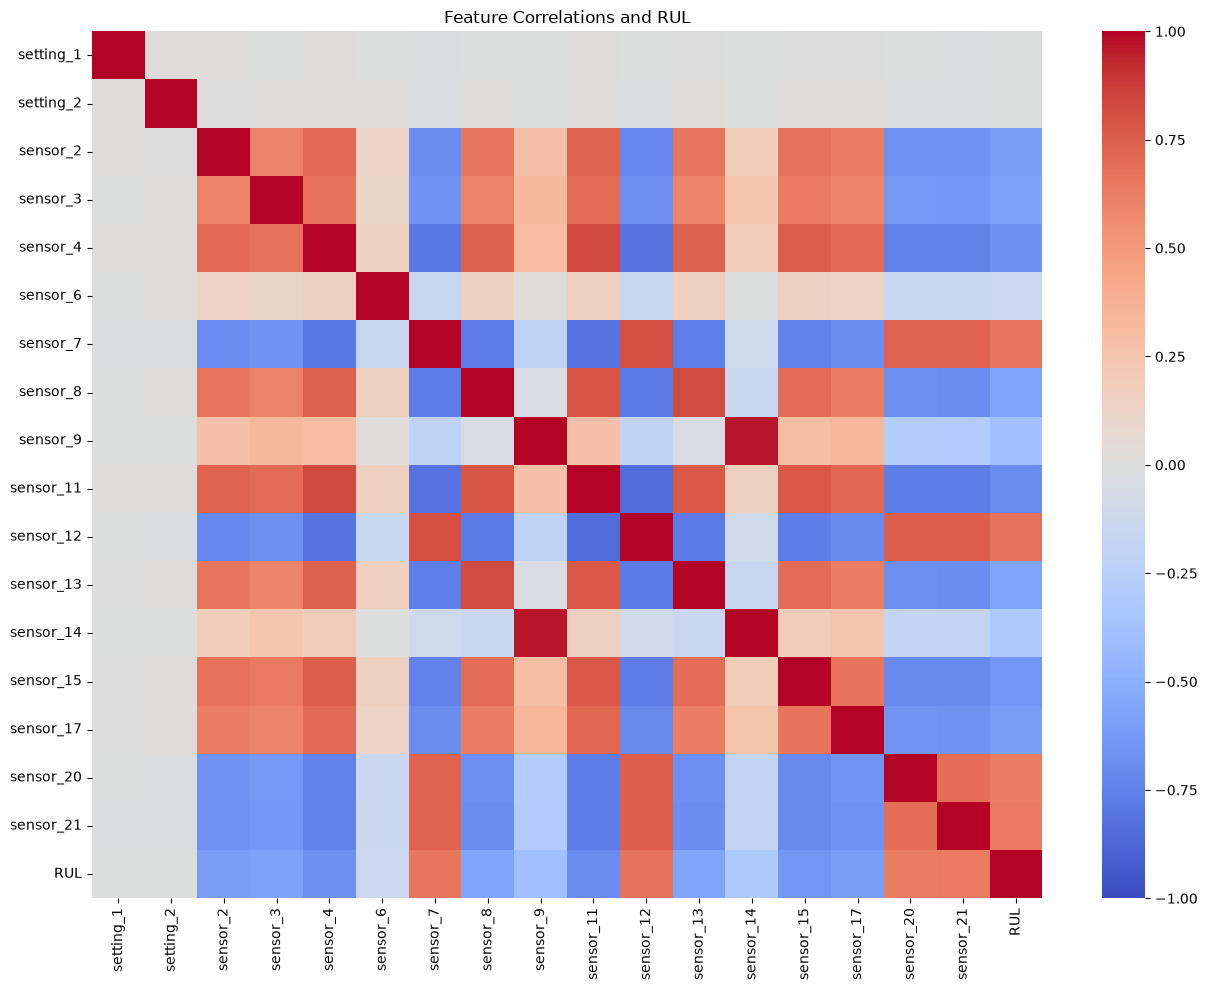

sensor_11   -0.696
sensor_4    -0.679
sensor_12    0.672
sensor_7     0.657
sensor_15   -0.643
sensor_21    0.636
sensor_20    0.629
sensor_2    -0.606
sensor_17   -0.606
sensor_3    -0.585
sensor_8    -0.564
sensor_13   -0.563
sensor_9    -0.390
sensor_14   -0.307
sensor_6    -0.128
setting_1   -0.003
setting_2   -0.002
Name: RUL, dtype: float64

In [ ]:
import seaborn as sns


plot_cols = [
    col for col in df.columns
    if col.startswith(("setting_", "sensor_"))
    and df[col].nunique() > 1
]

corr = df[plot_cols + ["RUL"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlations and RUL")
plt.tight_layout()
plt.show()

corr_with_rul = corr["RUL"].drop("RUL")

display(
    corr_with_rul
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .round(3)
)

In [ ]:
corr_with_rul = (
    cleaned.drop(columns=["engine_id"], errors="ignore")
    .corr(numeric_only=True)["RUL"]
    .drop("RUL")
    .dropna()
)

display(
    corr_with_rul
    .sort_values(key=lambda values: values.abs(), ascending=False)
    .round(3)
)

NameError: name 'cleaned' is not defined

In [ ]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### Feature Correlations
- Some sensors are positively correlated with RUL, while others are negatively correlated. Both operating settings show weak linear correlations with RUL.
- Strong correlations also exist between some sensors.
- We will evaluate the features through cross-validation before excluding any of them.

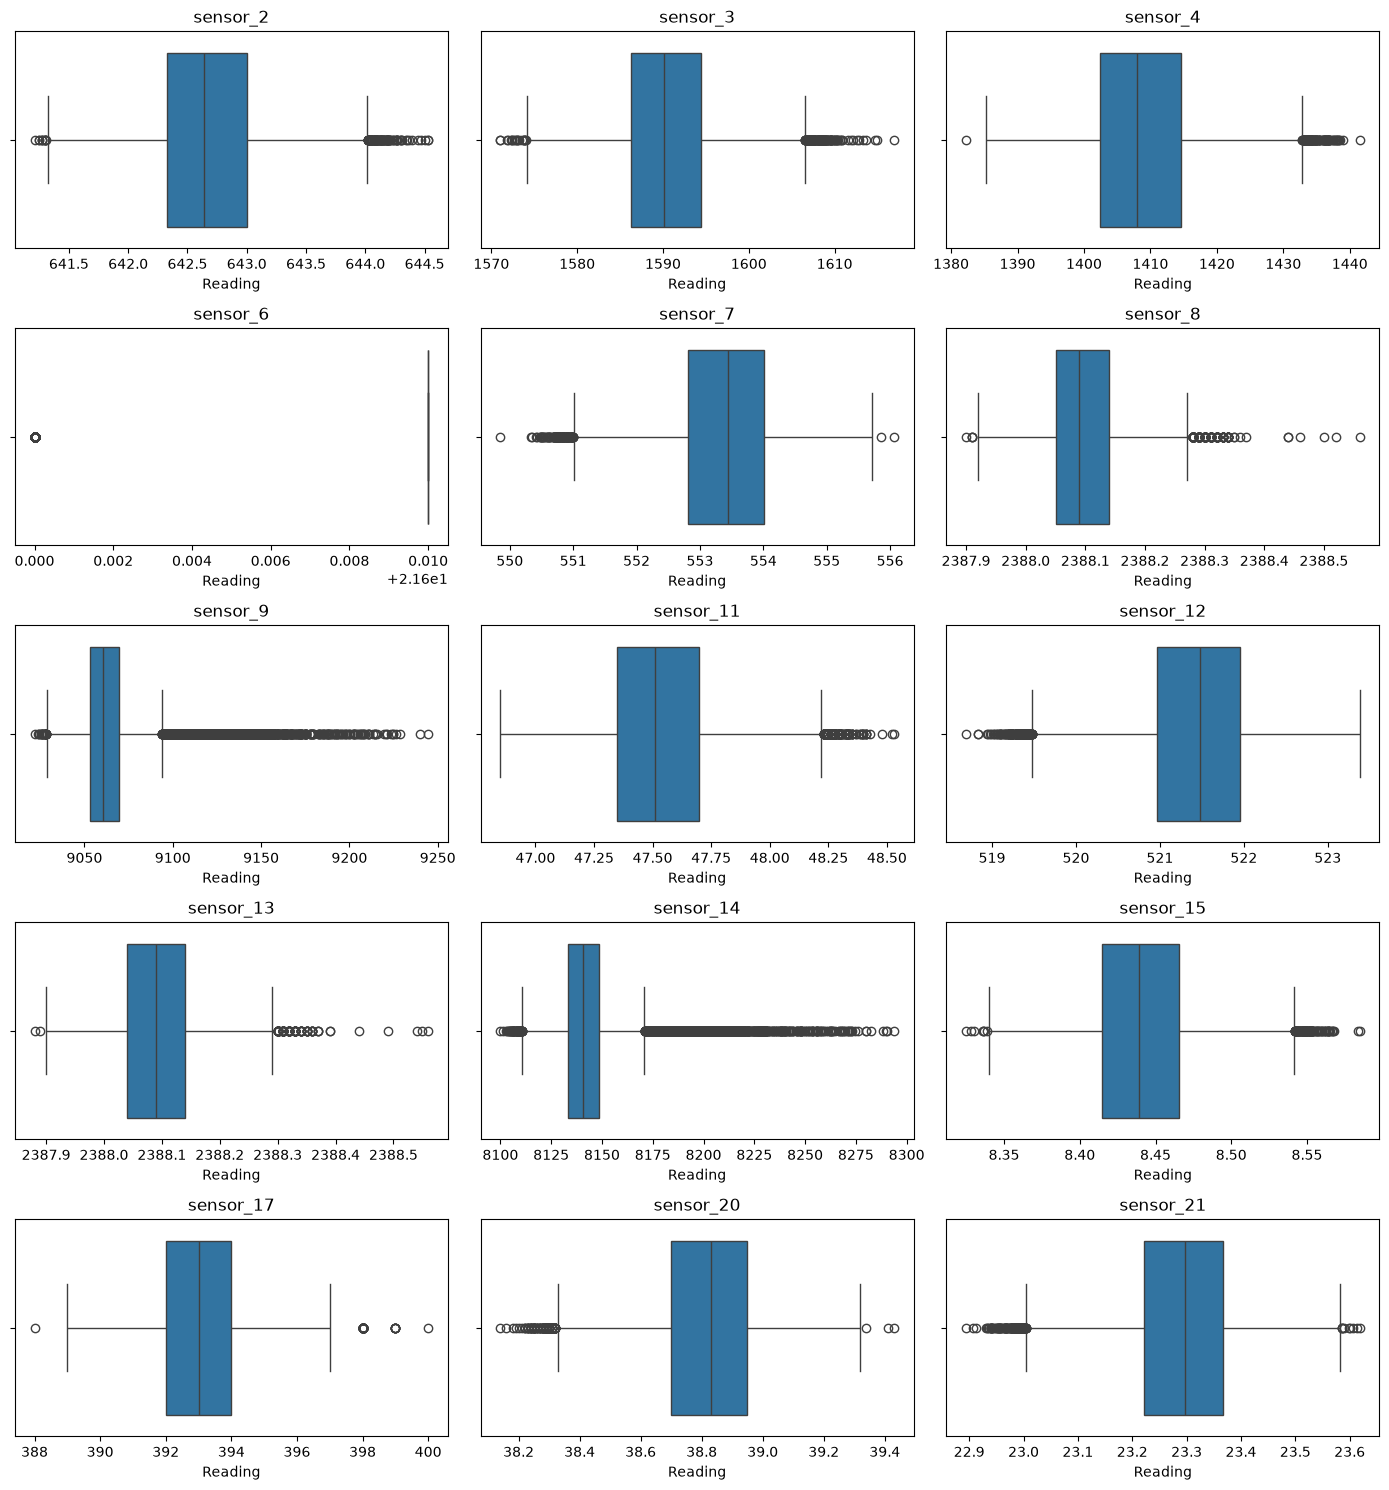

In [ ]:
sensor_cols = [
    col for col in df.columns
    if col.startswith("sensor_") and df[col].nunique() > 1
]

fig, axes = plt.subplots(5, 3, figsize=(14, 15))
axes = axes.flatten()

for ax, col in zip(axes, sensor_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Reading")

for ax in axes[len(sensor_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

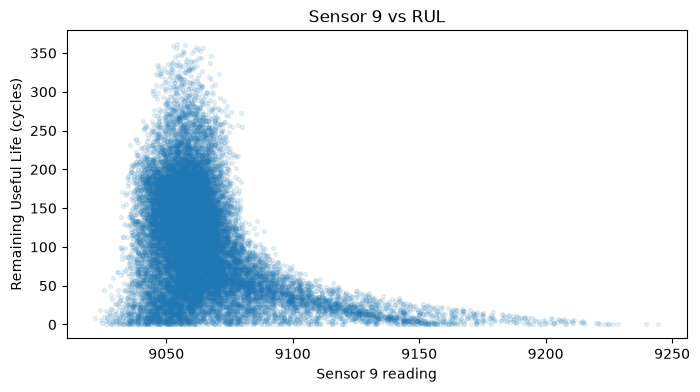

In [ ]:
plt.figure(figsize=(8, 4))

plt.scatter(df["sensor_9"], df["RUL"], alpha=0.1, s=8)

plt.xlabel("Sensor 9 reading")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title("Sensor 9 vs RUL")
plt.show()

In [ ]:
from pathlib import Path

clean_df = df.sort_values(
    ["engine_id", "cycle"]
).reset_index(drop=True)

output_path = Path("../Data/Cleaned/train_FD001_cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

clean_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", clean_df.shape)

Saved: ..\Data\Cleaned\train_FD001_cleaned.csv
Shape: (20631, 27)


## Data Issues and Solutions

### 1. Constant Columns

**Issue:** Seven columns contain a single unique value across all rows and therefore do not help distinguish between engine conditions.

**Solution:** Remove these columns from the processed dataset while keeping the original data unchanged.

**Columns:** sensor_1, setting_3, sensor_5, sensor_10, sensor_18, sensor_19, sensor_16.

In [ ]:

constant_cols = [
    "sensor_1", "setting_3", "sensor_5", "sensor_10",
    "sensor_18", "sensor_19", "sensor_16"
]


clean_df = df.drop(columns=constant_cols).copy()

print("Before:", df.shape)
print("After:", clean_df.shape)

clean_df.head()

Before: (20631, 27)
After: (20631, 20)


,engine_id,cycle,setting_1,setting_2,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,641.82,1589.70,1400.60,21.61,554.36,2388.06,9046.19,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,191
1,1,2,0.0019,-0.0003,642.15,1591.82,1403.14,21.61,553.75,2388.04,9044.07,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,190
2,1,3,-0.0043,0.0003,642.35,1587.99,1404.20,21.61,554.26,2388.08,9052.94,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,189
3,1,4,0.0007,0.0000,642.35,1582.79,1401.87,21.61,554.45,2388.11,9049.48,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,642.37,1582.85,1406.22,21.61,554.00,2388.06,9055.15,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,187


In [ ]:
from pathlib import Path

# التأكد من وجود التارقت ورقم المحرك
assert {"RUL", "engine_id", "cycle"}.issubset(clean_df.columns)


output_path = Path("../Data/Cleaned/train_FD001_cleaned.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

clean_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Shape:", clean_df.shape)

Saved: ..\Data\Cleaned\train_FD001_cleaned.csv
Shape: (20631, 20)


## Preprocessing Summary

- No missing values or duplicate records were found.
- Seven constant columns were removed.
- Potential outliers were retained because they may contain degradation information.
- RUL was calculated for each engine using its final cycle minus its current cycle.
- No categorical encoding was required.
- Scaling will be applied within model pipelines during cross-validation.
- The processed dataset was saved to Data/Cleaned/train_FD001_cleaned.csv.